In [84]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from imblearn.over_sampling import RandomOverSampler
from sklearn.preprocessing import StandardScaler
import copy
import seaborn as sns
import tensorflow as tf
from sklearn.linear_model import LinearRegression

In [85]:
dataset_cols = ["bike_count", "hour", "temp", "humidity", "wind", "visibility", "dew_pt_temp", "radiation", "rain", "snow", "functional"]
df = pd.read_csv("SeoulBikeData.csv").drop(["Date", "Holiday", "Seasons"], axis=1)

In [86]:
df.columns = dataset_cols
df["functional"] = (df["functional"] == "Yes").astype(int)
df = df[df["hour"] == 12]
df = df.drop(["hour"], axis=1)

In [87]:
df.head()

,bike_count,temp,humidity,wind,visibility,dew_pt_temp,radiation,rain,snow,functional
12,449,1.7,23,1.4,2000,-17.2,1.11,0.0,0.0,1
36,479,4.3,41,1.3,1666,-7.8,1.09,0.0,0.0,1
60,333,5.8,85,1.7,349,3.4,0.43,0.0,0.0,1
84,393,-0.3,38,4.8,1823,-12.9,1.11,0.0,0.0,1
108,321,-2.3,25,0.0,1962,-19.7,0.00,0.0,0.0,1


Index(['Date', 'Rented Bike Count', 'Hour', 'Temperature(C)',
       'Humidity(percentage)', 'Wind speed (m/s)', 'Visibility (10m)',
       'Dew point temperature(C)', 'Solar Radiation (MJ/m2)', 'Rainfall(mm)',
       'Snowfall (cm)', 'Seasons', 'Holiday', 'Functioning Day'],
      dtype='str')


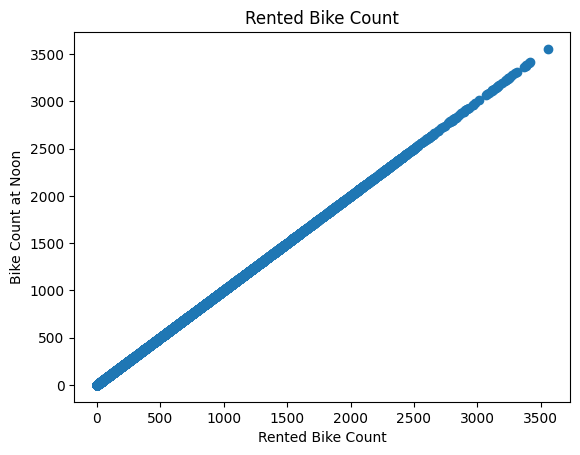

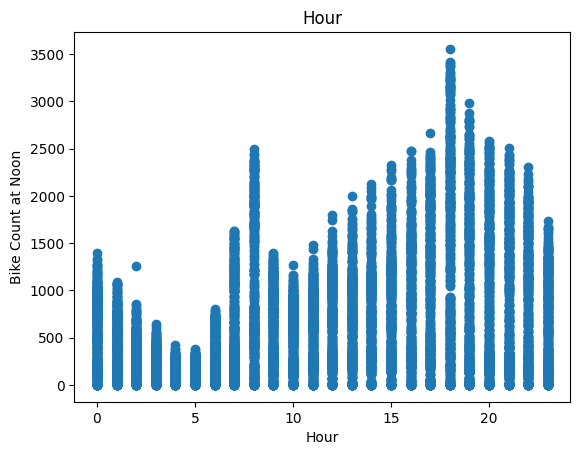

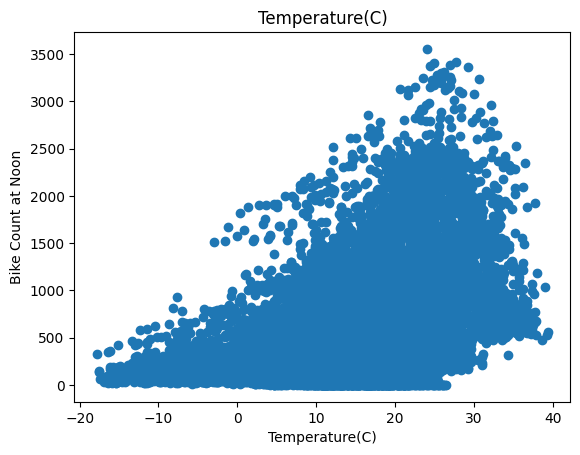

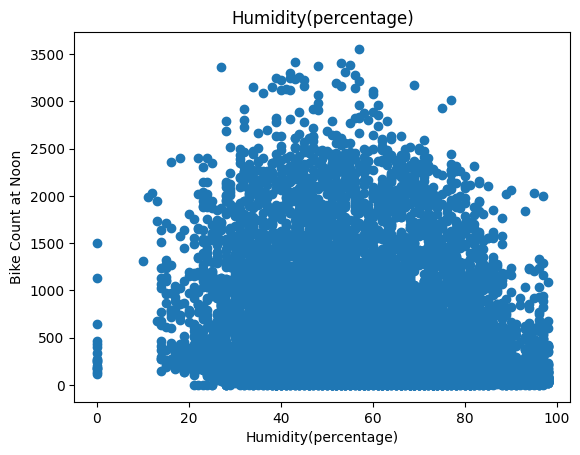

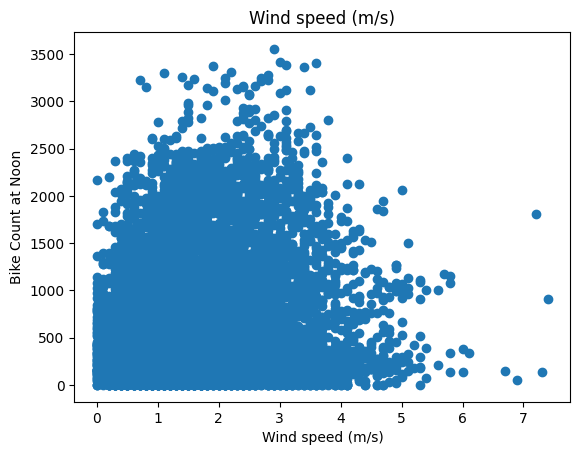

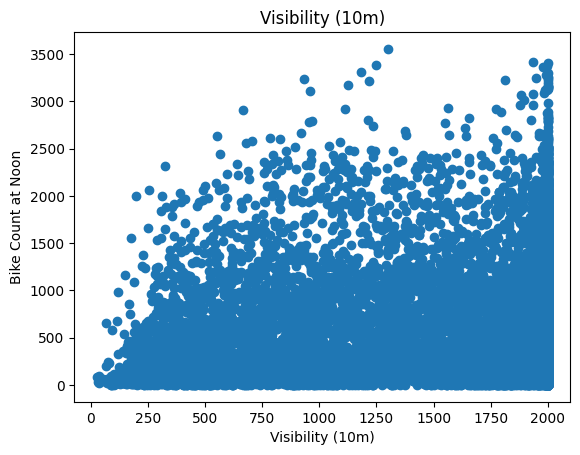

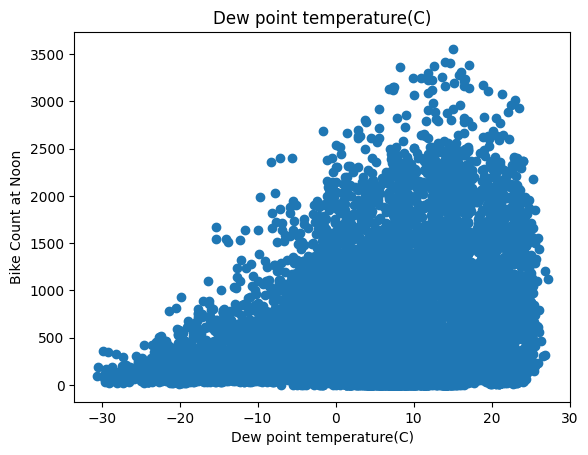

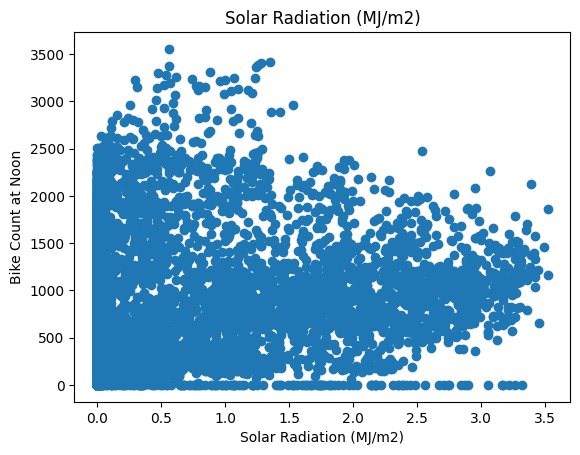

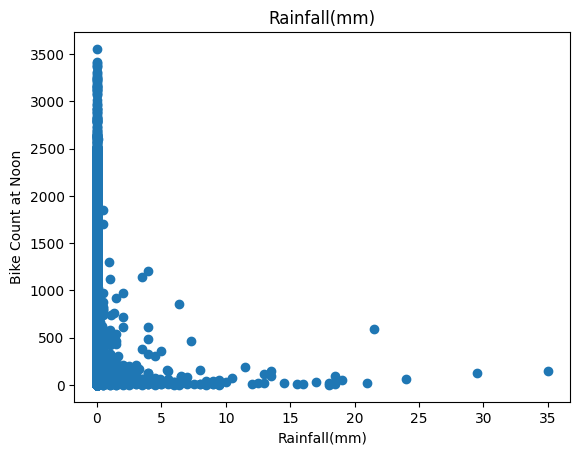

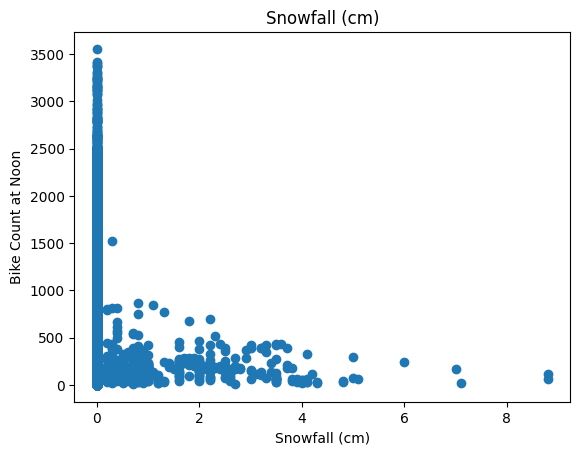

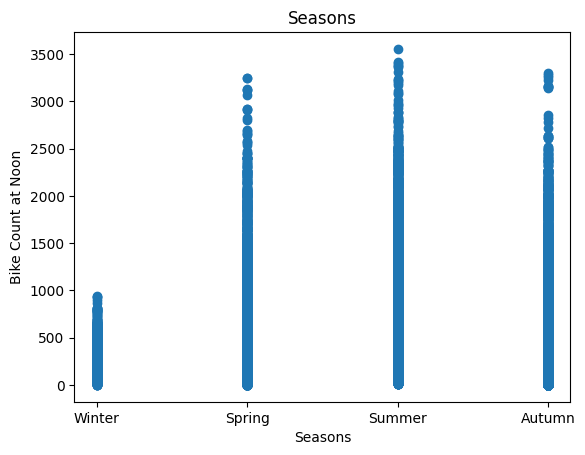

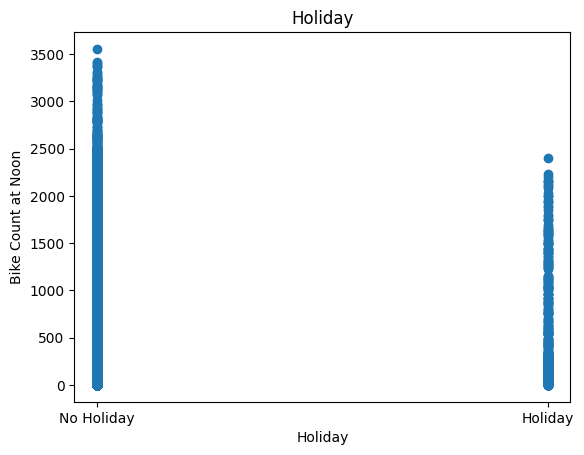

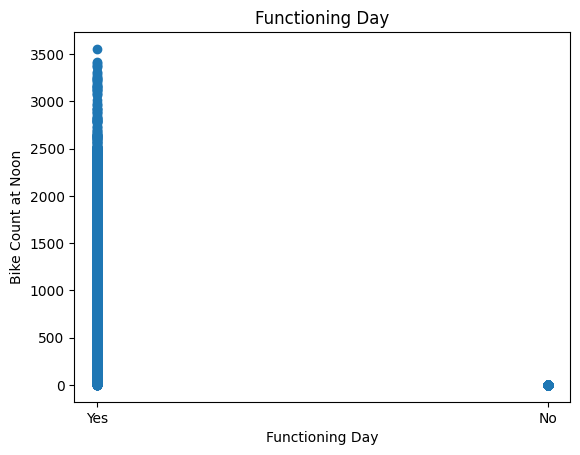

In [88]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('SeoulBikeData.csv')
print(df.columns) 

for label in df.columns[1:]:
     plt.scatter(df[label], df["Rented Bike Count"]) 
     plt.title(label)
     plt.ylabel("Bike Count at Noon")
     plt.xlabel(label)
     plt.show()

In [89]:
df = df.drop(["Wind speed (m/s)", "Visibility (10m)", "Functioning Day"], axis=1)

In [90]:
df.head()

,Date,Rented Bike Count,Hour,Temperature(C),Humidity(percentage),Dew point temperature(C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday
0,1/12/2017,254,0,-5.2,37,-17.6,0.0,0.0,0.0,Winter,No Holiday
1,1/12/2017,204,1,-5.5,38,-17.6,0.0,0.0,0.0,Winter,No Holiday
2,1/12/2017,173,2,-6.0,39,-17.7,0.0,0.0,0.0,Winter,No Holiday
3,1/12/2017,107,3,-6.2,40,-17.6,0.0,0.0,0.0,Winter,No Holiday
4,1/12/2017,78,4,-6.0,36,-18.6,0.0,0.0,0.0,Winter,No Holiday


Train/Valid/Test dataset

In [91]:
import numpy as np
train,vaL,test = np.split(df.sample(frac=1),[int(0.6*len(df)),int(0.8*len(df))])

In [92]:
import copy

def get_xy(dataframe, y_label, x_labels=None):
    dataframe = copy.deepcopy(dataframe)

    if x_labels is None:
        X = dataframe.drop(columns=[y_label]).values
    else:
        X = dataframe[x_labels].values

    y = dataframe[y_label].values

    return dataframe, X, y

In [93]:
print(type(df))
print(type(train))
print(df.columns.tolist())

<class 'pandas.DataFrame'>
<class 'numpy.ndarray'>
['Date', 'Rented Bike Count', 'Hour', 'Temperature(C)', 'Humidity(percentage)', 'Dew point temperature(C)', 'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'Seasons', 'Holiday']


In [94]:
from sklearn.model_selection import train_test_split

train, temp_data = train_test_split(
    df, test_size=0.4, random_state=42
)

val, test = train_test_split(
    temp_data, test_size=0.5, random_state=42
)

In [95]:
print(type(train))
print(type(val))
print(type(test))

<class 'pandas.DataFrame'>
<class 'pandas.DataFrame'>
<class 'pandas.DataFrame'>


In [96]:
import copy

def get_xy(dataframe, y_label, x_labels=None):
    dataframe = copy.deepcopy(dataframe)

    if x_labels is None:
        X = dataframe.drop(columns=[y_label]).values
    else:
        X = dataframe[x_labels].values

    y = dataframe[y_label].values

    return dataframe, X, y

In [97]:
_, X_train_temp, y_train_temp = get_xy(
    train, "Rented Bike Count", x_labels=["Temperature(C)"]
)

_, X_val_temp, y_val_temp = get_xy(
    val, "Rented Bike Count", x_labels=["Temperature(C)"]
)

_, X_test_temp, y_test_temp = get_xy(
    test, "Rented Bike Count", x_labels=["Temperature(C)"]
)

In [98]:
print("Training:", X_train_temp.shape, y_train_temp.shape)
print("Validation:", X_val_temp.shape, y_val_temp.shape)
print("Testing:", X_test_temp.shape, y_test_temp.shape)

Training: (5256, 1) (5256,)
Validation: (1752, 1) (1752,)
Testing: (1752, 1) (1752,)


In [99]:
from sklearn.linear_model import LinearRegression
temp_reg = LinearRegression()
temp_reg.fit(X_train_temp, y_train_temp)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[29.22]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,326.4
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[862.85]


In [100]:
temp_reg.score(X_test_temp, y_test_temp)

0.2902767426172206

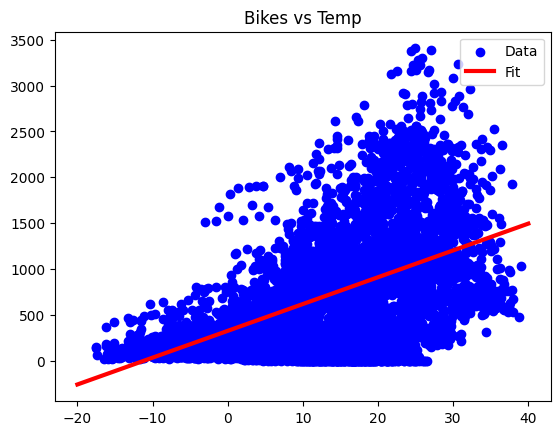

In [101]:
import matplotlib.pyplot as plt
import numpy as np

plt.scatter(X_train_temp, y_train_temp, label="Data", color="blue")

x = np.linspace(-20, 40, 100)

plt.plot(
    x,
    temp_reg.predict(x.reshape(-1, 1)),
    label="Fit",
    color="red",
    linewidth=3
)

plt.legend()
plt.title("Bikes vs Temp")
plt.show()

In [117]:
print(df.columns.tolist())

['Date', 'Rented Bike Count', 'Hour', 'Temperature(C)', 'Humidity(percentage)', 'Dew point temperature(C)', 'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'Seasons', 'Holiday']


In [118]:
import pandas as pd

df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)

df["Day"] = df["Date"].dt.day
df["Month"] = df["Date"].dt.month

df = df.drop(columns=["Date"])

df = pd.get_dummies(
    df,
    columns=["Seasons", "Holiday"],
    dtype=int
)

In [119]:
from sklearn.model_selection import train_test_split

train, temp_data = train_test_split(
    df, test_size=0.4, random_state=42
)

val, test = train_test_split(
    temp_data, test_size=0.5, random_state=42
)

In [120]:
target = "Rented Bike Count"

x_labels = [col for col in df.columns if col != target]

_, X_train_all, y_train_all = get_xy(
    train, target, x_labels=x_labels
)

_, X_val_all, y_val_all = get_xy(
    val, target, x_labels=x_labels
)

_, X_test_all, y_test_all = get_xy(
    test, target, x_labels=x_labels
)

In [121]:
from sklearn.linear_model import LinearRegression

all_reg = LinearRegression()
all_reg.fit(X_train_all, y_train_all)

print("Training score:", all_reg.score(X_train_all, y_train_all))
print("Validation score:", all_reg.score(X_val_all, y_val_all))
print("Testing score:", all_reg.score(X_test_all, y_test_all))

Training score: 0.4973829902242425
Validation score: 0.47388171089435993
Testing score: 0.46821543751172034


Regression with neural net

In [125]:
def plot_loss(history):
  plt.plot(history.history['loss'], label='loss')
  plt.plot(history.history['val_loss'], label='val_loss')
  plt.xlabel('Epoch')
  plt.ylabel('MSE')
  plt.legend()
  plt.grid(True)
  plt.show()

In [126]:
temp_normalizer = tf.keras.layers.Normalization(input_shape=(1,), axis=None)
temp_normalizer.adapt(X_train_temp.reshape(-1))

In [132]:
temp_nn_model = tf.keras.Sequential((
    temp_normalizer,
    tf.keras.layers.Dense(1)
))

In [133]:
temp_nn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.1),
    loss="mean_squared_error"
)

In [137]:
history = temp_nn_model.fit(
    X_train_temp,
    y_train_temp,
    validation_data=(X_val_temp, y_val_temp),
    epochs=100,
    batch_size=32,
    verbose=0
)

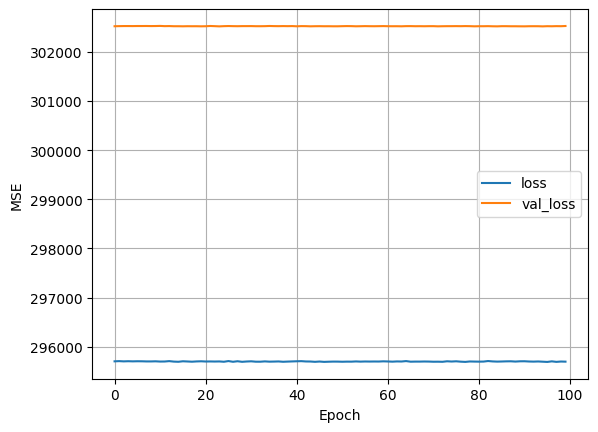

In [138]:
plot_loss(history)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


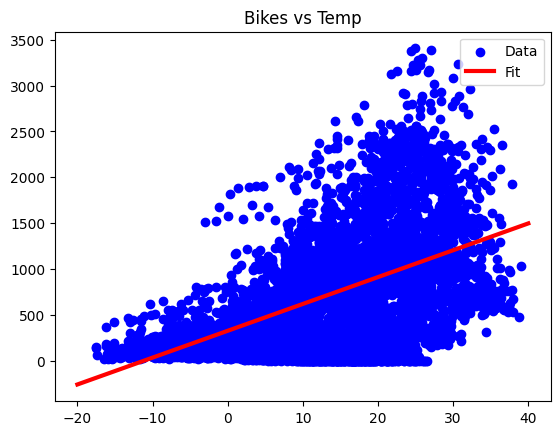

In [140]:
import matplotlib.pyplot as plt
import numpy as np

plt.scatter(X_train_temp, y_train_temp, label="Data", color="blue")

x = np.linspace(-20, 40, 100)

plt.plot(
    x,
    temp_nn_model.predict(x.reshape(-1, 1)),
    label="Fit",
    color="red",
    linewidth=3
)

plt.legend()
plt.title("Bikes vs Temp")
plt.show()

Neural Net